In [1]:
# Project settings and paths: config.py is in the project root (this also makes the modules in src/ importable)
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())))
import config

# Standard libraries
import json
import numpy as np
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from functools import partial
from itertools import product

# Specific libraries
import nibabel as nib
import seaborn as sns
from dipy.denoise.localpca import mppca

# Import custom modules
import file_io as fio
import dicom_load as dcmload
import registration as reg
import temperature as temp
import denoise as dn

In [2]:
# Define directories
CALIB_DIR = config.CALIBRATION_DIR
SCAN_DIR = CALIB_DIR / "scan_data"
TEMP_DIR = CALIB_DIR / "temperature_data"
OUTPUT_DIR = CALIB_DIR / "derivatives"
testname = CALIB_DIR.stem

if not CALIB_DIR.is_dir():
    raise NotADirectoryError(f"Expected a directory, got: {CALIB_DIR}") 
if not SCAN_DIR.is_dir():
    raise NotADirectoryError(f"{CALIB_DIR.stem} doesn't contain subdirectory named {SCAN_DIR.stem}") 
if not TEMP_DIR.is_dir():
    raise NotADirectoryError(f"{CALIB_DIR.stem} doesn't contain subdirectory named {TEMP_DIR.stem}") 

OUTPUT_DIR.mkdir(exist_ok=True)

### LOAD & UNPACK

In [3]:
# Load in data and save basic features 
dicom_fnames = fio.scrape_files(SCAN_DIR, filetype=["MRe", "dcm"])
dicom_fnames.sort(key = lambda x: dcmload.dicom_scantime(x))
print(f"The full dataset contains {len(dicom_fnames)} DICOM files")
dataset_unpacked = list(map(dcmload.process_dicom, dicom_fnames))
dataset_df = pd.DataFrame(dataset_unpacked)
print("Scans unpacked into pandas DataFrame structure")

The full dataset contains 460 DICOM files
Scans unpacked into pandas DataFrame structure


### PAIR W/ TEMP DATA

Full dataset contains 460 scans
Removing 0 scans - don't have corresponding temperature data
'Temperature trimmed' dataset contains 460 scans


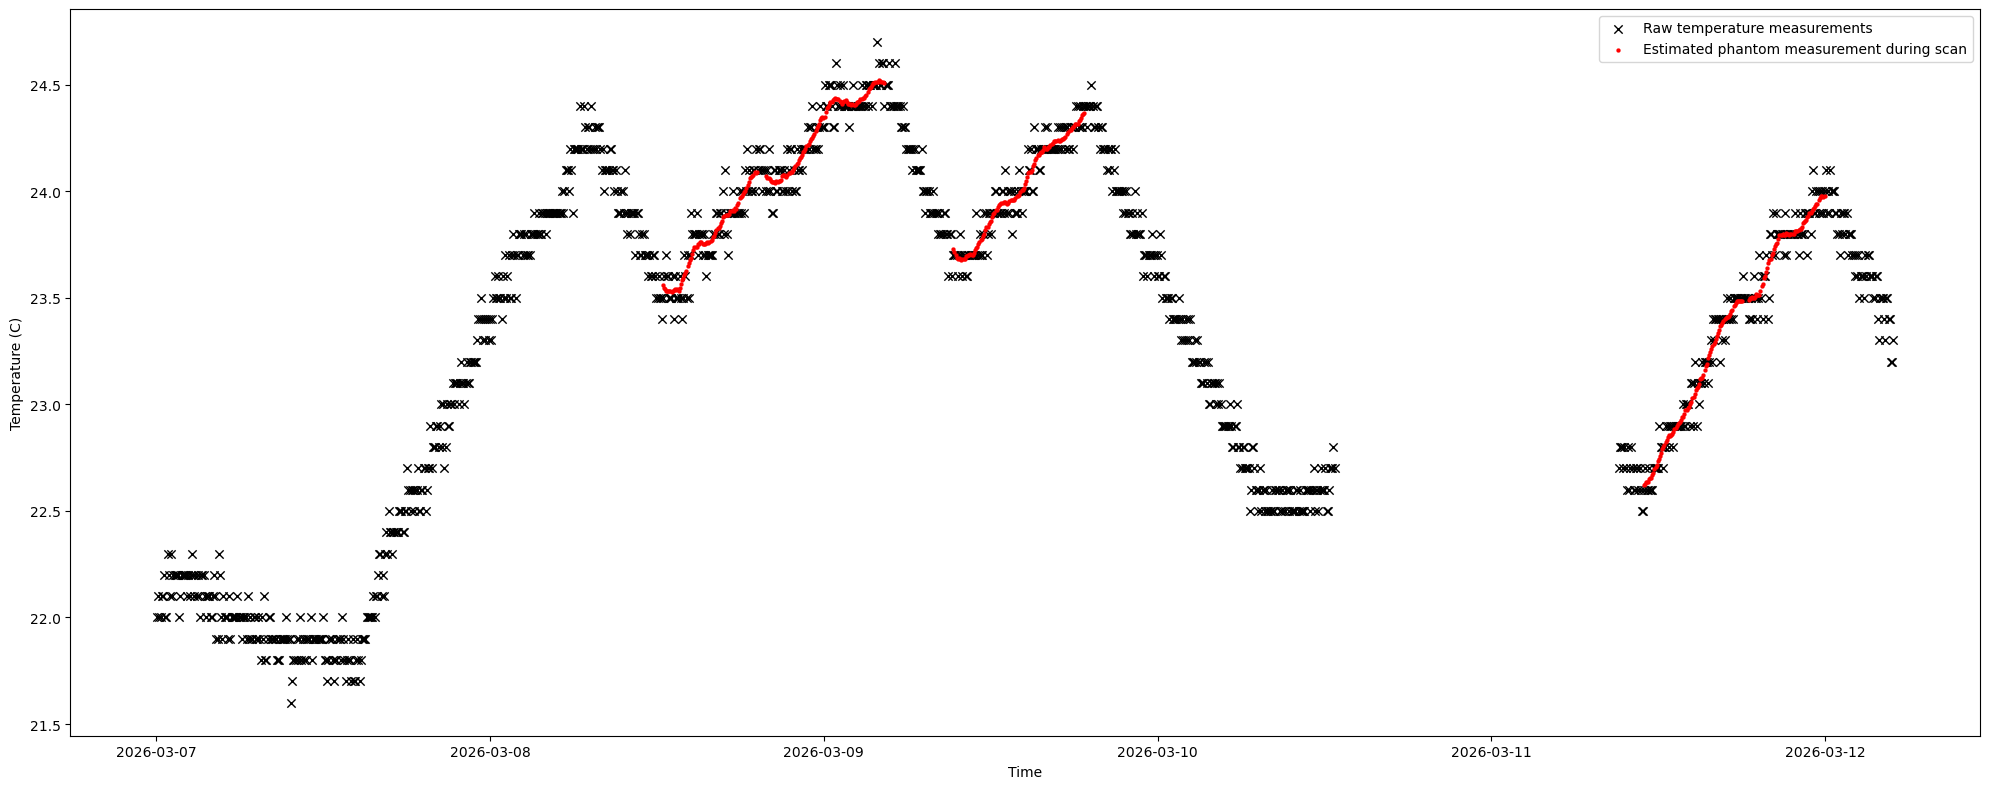

In [4]:
# Now pair scans with their temperature measurements and remove any scans without valid temperature measurements
temp_fname = TEMP_DIR / "temperatures.csv"
temp_log = np.loadtxt(temp_fname, dtype=str, delimiter=",", skiprows=1)
temp_log_dt = [[dcmload.convert_timestamp(datetime_string), float(temp)] for datetime_string, temp in temp_log]
temp_log_dt_np = np.array(temp_log_dt)

dataset_df["temperature"] = dataset_df["scan_time"].apply(partial(temp.estimate_temp, temp_log=temp_log_dt, time_window_minutes=90, f_past=0.5, n_min=None))
print(f"Full dataset contains {dataset_df.shape[0]} scans")

n_lacking_temp = np.count_nonzero(dataset_df["temperature"].isna())
print(f"Removing {n_lacking_temp} scans - don't have corresponding temperature data")

valid_df = dataset_df[dataset_df["temperature"].notna()].copy()
print(f"'Temperature trimmed' dataset contains {valid_df.shape[0]} scans")

fig, ax = plt.subplots(1, 1, figsize=(20,8))
ax.scatter(temp_log_dt_np[:,0], 
           temp_log_dt_np[:,1], 
           marker="x", 
           linewidth=1 , 
           c="k", 
           label="Raw temperature measurements")

ax.scatter(valid_df["scan_time"].values, 
           valid_df["temperature"].values, 
           marker=".", 
           linewidth=0.1, 
           c="r",
           label="Estimated phantom measurement during scan")
ax.legend()
ax.set_ylabel("Temperature (C)")
ax.set_xlabel("Time")
fig.tight_layout()
plt.show()

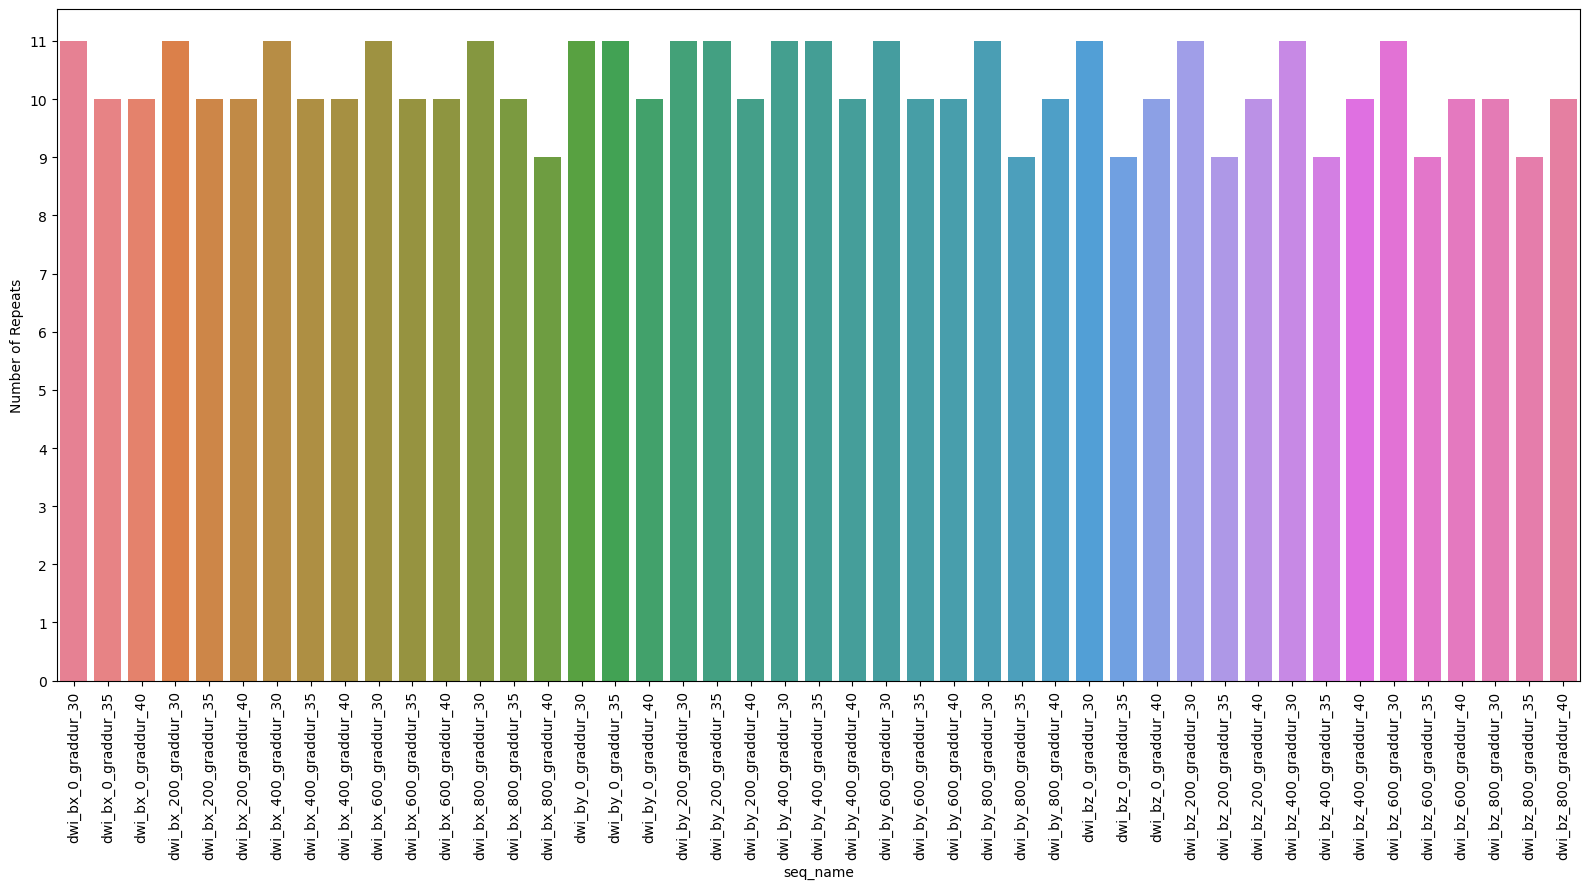

In [5]:
def plot_num_of_repeats(df, col_name):

    num_repeats = df.groupby(col_name).size().rename("count").reset_index()

    fig, ax = plt.subplots(figsize=(16, 9))
    sns.barplot(data=num_repeats, x=col_name, y="count", hue=col_name, palette="husl", ax=ax)

    # Tidy up axes
    ax.set_xticks(np.arange(num_repeats.values.shape[0]), num_repeats[col_name])
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha="center")
    ax.set_yticks(range(0, num_repeats["count"].values.max() + 1))
    ax.set_ylabel("Number of Repeats")
    fig.tight_layout()

    plt.show()

plot_num_of_repeats(valid_df, "seq_name")


### MPPCA DENOISING

In [6]:

# ----------------------------------
# RUN ON SUBGROUPS INDEPENDENTLY
# ----------------------------------

df_list = []
n_iter = len(valid_df["dwi_grad_duration"].unique())

for i, dur in enumerate(valid_df["dwi_grad_duration"].unique(), start=1):

    print(f"Denoising iteration: {i} / {n_iter}")
    # Extract scans from dataframe
    graddur_df = valid_df[valid_df["dwi_grad_duration"] == dur].copy()
    raw_scans = np.stack(graddur_df["image"].values, axis=-1)

    denoised_scans = dn.apply_mppca(raw_scans, default_kernel=False, kernel="9,9,9")
    graddur_df["mppca_image"] = list(np.transpose(denoised_scans, [3,0,1,2]))
    df_list.append(graddur_df)

denoised_df = pd.concat(df_list).reset_index(drop=True)
denoised_df.sort_values(by="scan_time", axis="index", ignore_index=True, inplace=True)


"""# ----------------------------------
# RUN ON FULL DATASET SIMULTANEOUSLY
# ----------------------------------

raw_scans = np.stack(valid_df["image"].values, axis=-1)
denoised_scans = dn.apply_mppca(raw_scans, default_kernel=True, kernel=None)
denoised_df = valid_df.copy()
denoised_df["mppca_image"] = list(np.transpose(denoised_scans, [3,0,1,2]))"""

Denoising iteration: 1 / 3


100%|██████████| 225388/225388 [04:15<00:00, 880.70it/s] 


Denoising iteration: 2 / 3


100%|██████████| 225388/225388 [04:57<00:00, 758.45it/s]


Denoising iteration: 3 / 3


100%|██████████| 225388/225388 [04:32<00:00, 826.67it/s] 


'# ----------------------------------\n# RUN ON FULL DATASET SIMULTANEOUSLY\n# ----------------------------------\n\nraw_scans = np.stack(valid_df["image"].values, axis=-1)\ndenoised_scans = dn.apply_mppca(raw_scans, default_kernel=True, kernel=None)\ndenoised_df = valid_df.copy()\ndenoised_df["mppca_image"] = list(np.transpose(denoised_scans, [3,0,1,2]))'

### REGISTRATION

In [7]:
# Extract images from dataframe
raw_4d = np.stack(denoised_df["image"].values, axis=-1)
mppca_4d = np.stack(denoised_df["mppca_image"].values, axis=-1)
aff_0 = denoised_df["affine"].values[0]
spacing_0 = reg.spacing_from_affine(aff_0)

# Extract b-values in order to be able to identify b=0 scan to register other scans to
bvals = denoised_df["b_value"].values

# Perform registration:
# The registration transformations are estimated on the MP-PCA denoised scans, as the high-b noisy scans
# don't have enough SNR to be registered reliably.
# The function returns a registered 4D image array, a numpy array of indices for which registration failed
# and the list of transformations (one per scan).
reg_mppca_4d, i_drop, transforms = reg.register_to_b0(data_4d=mppca_4d, 
                                                      bvals=bvals, 
                                                      spacing=spacing_0,
                                                      b0_threshold=5,
                                                      return_transforms=True)

# The same transformations are then applied to the original (noisy) scans.
# This gives us two registered datasets: denoised and noisy.
reg_raw_4d = reg.apply_registration(data_4d=raw_4d, 
                                    transforms=transforms, 
                                    spacing=spacing_0)

# Create a new dataframe with only the measurements that were successfully
# registered and append columns for the registered scans and the transformations used
reg_df = denoised_df.drop(index=i_drop).reset_index(drop=True)
reg_df["reg_mppca_image"] = list(np.transpose(reg_mppca_4d, (3,0,1,2))) # registered, denoised
reg_df["reg_image"] = list(np.transpose(reg_raw_4d, (3,0,1,2)))         # registered, noisy
reg_df["transform"] = [t for t in transforms if t is not None]

unreg_df = denoised_df.loc[i_drop].reset_index(drop=True)

Registering DWI images to b=0 image:  82%|████████▏ | 376/460 [01:59<00:37,  2.27it/s]

Failed to stabilise registration, returning original moving image


Registering DWI images to b=0 image: 100%|██████████| 460/460 [02:26<00:00,  3.13it/s]


Registration complete


Applying registration transforms: 100%|██████████| 460/460 [00:02<00:00, 226.54it/s]


### CREATE b=0 MASK

In [8]:
b0_threshold = 5

# Mask is created from the registered denoised b=0 scans
b0_scans = np.stack(reg_df[reg_df["b_value"] < b0_threshold]["reg_mppca_image"].values, axis=-1)
b0_avg = np.mean(b0_scans, axis=-1)
b0_mask = reg.get_mask(b0_avg, lt_percentile=55)

#px.imshow(b0_mask, animation_frame=2, zmin=0, zmax=1, height=800, width=1000, title="b=0 mask")

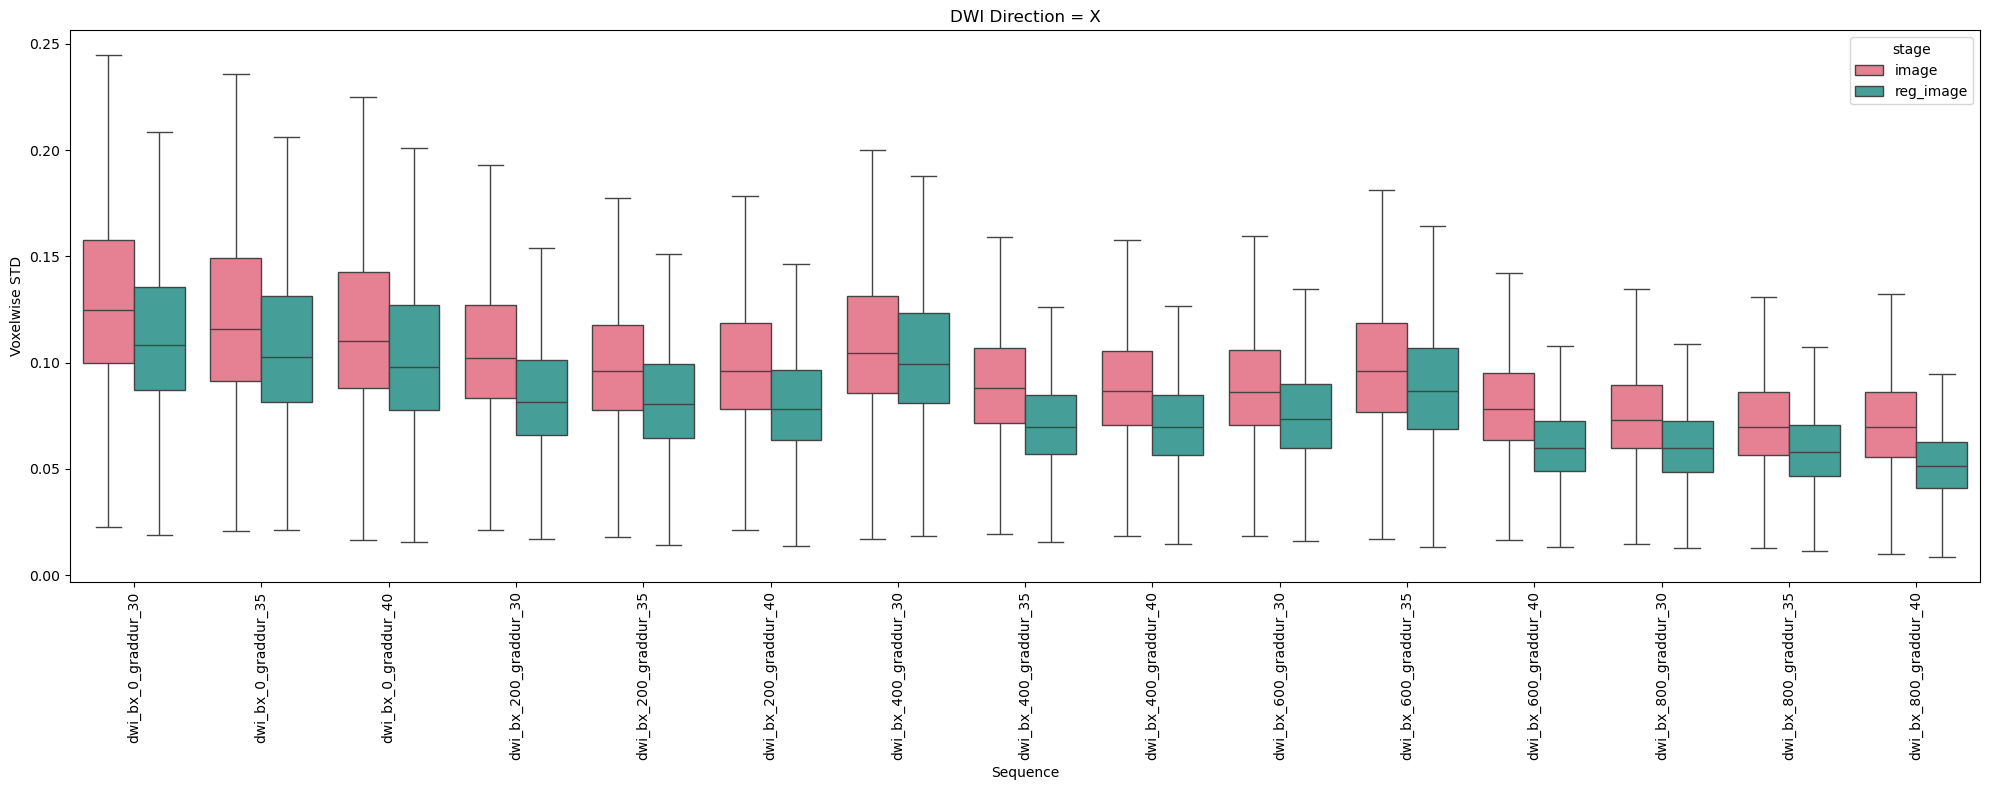

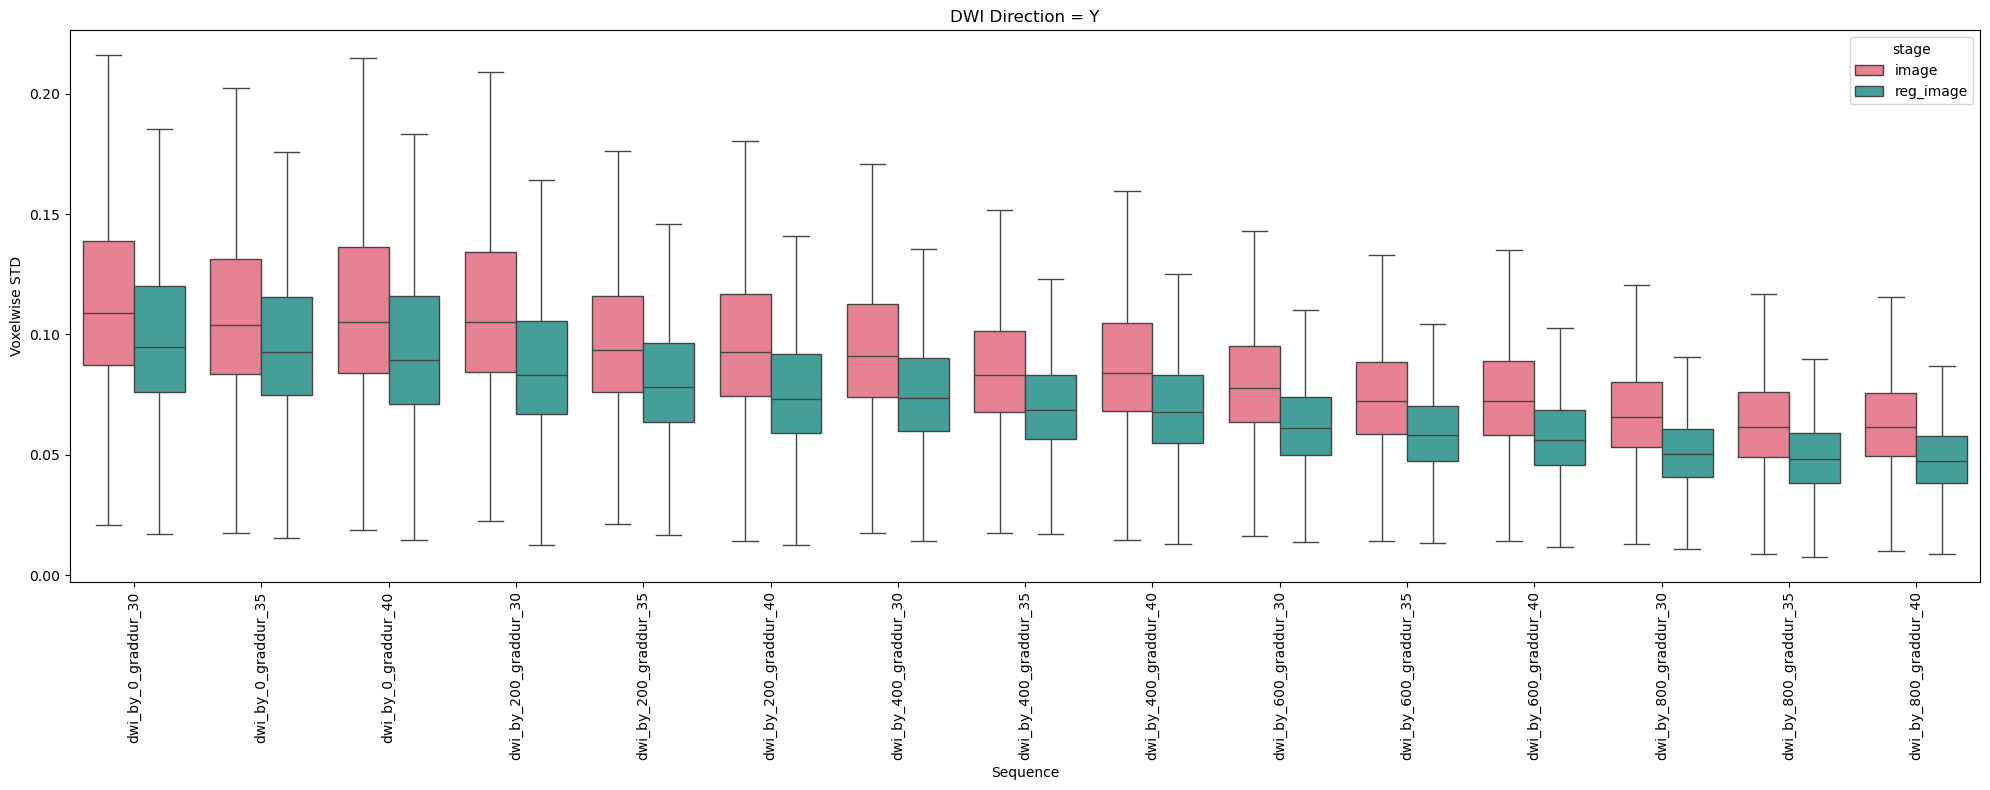

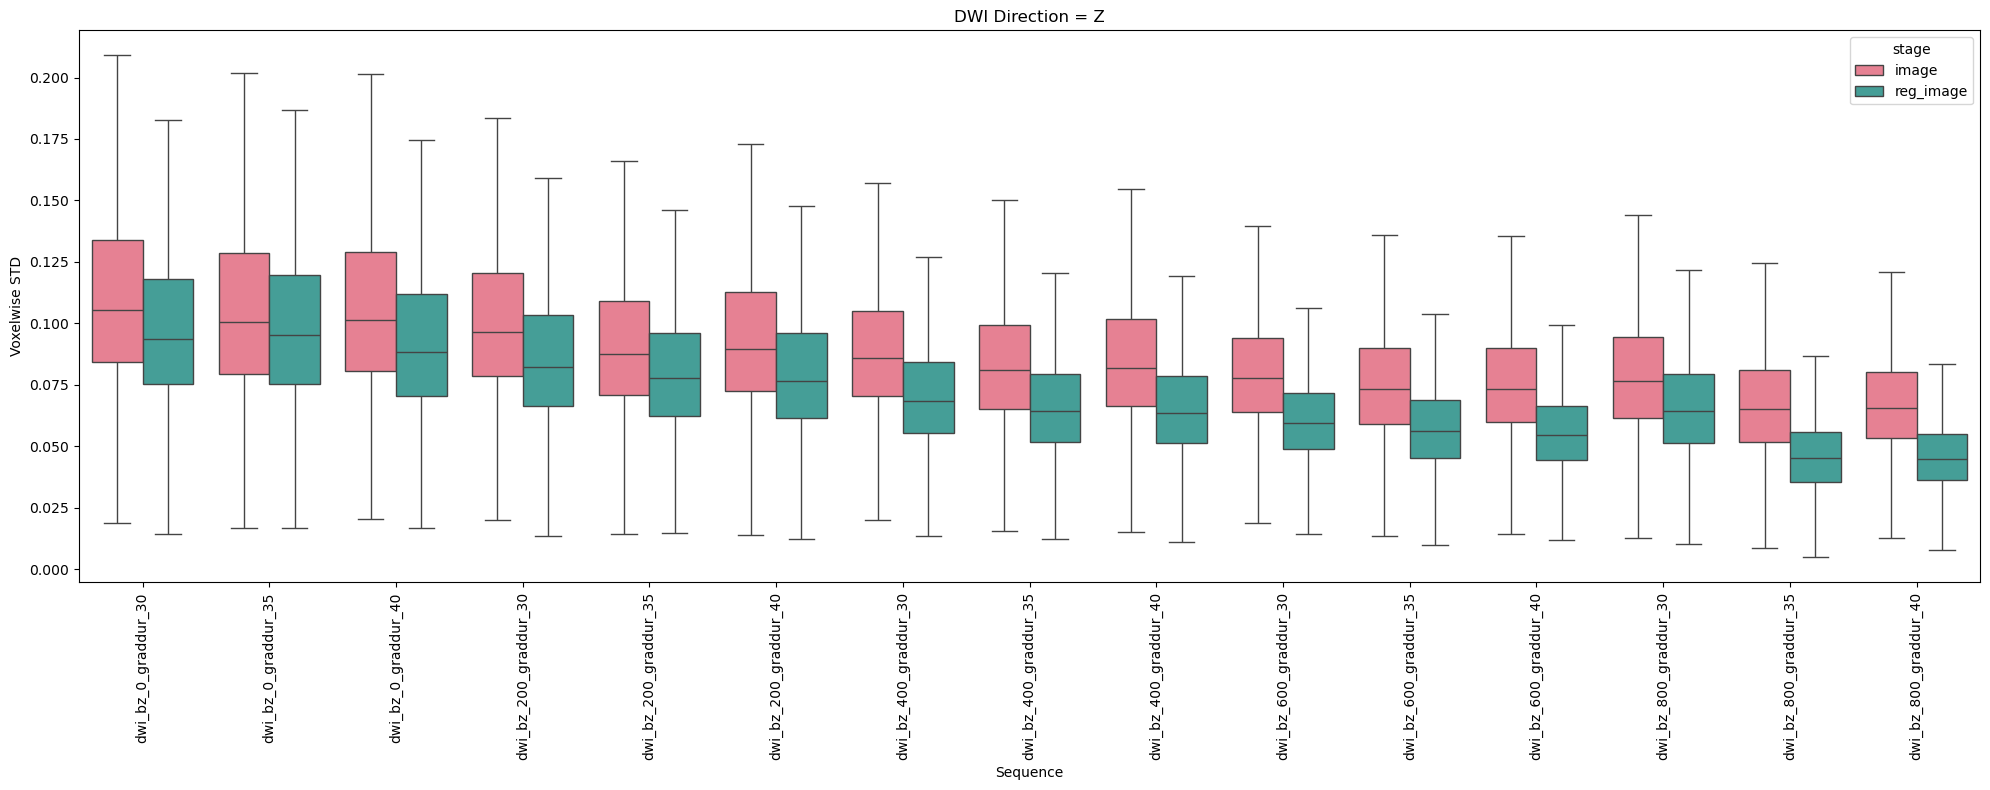

In [9]:
# This cell is for plotting the standard deviation across repeats for each sequence
# pre and post registration to check we are seeing an improvement in as expected
def voxel_std_plot(df, cat_1, cat_2, groupby="seq_name", mask=None):

    rows = []

    if mask is None:
        _mask = np.ones_like(df[cat_1].values[0]).astype(bool)
    else:
        _mask = mask.astype(bool)

    for sn, subset_df in df.groupby(groupby):
        
        img_1 = np.stack(subset_df[cat_1].values)
        img_2  = np.stack(subset_df[cat_2].values)
        axis = subset_df["dwi_direction"].unique()[0]

        std_1 = np.std(img_1, axis=0)
        std_2  = np.std(img_2, axis=0)

        std_1_vals = std_1[_mask]
        std_2_vals = std_2[_mask]

        rows.append(pd.DataFrame({
            "seq_name": sn,
            "stage": str(cat_1),
            "std_value": std_1_vals,
            "dwi_direction": axis
        }))

        rows.append(pd.DataFrame({
            "seq_name": sn,
            "stage": str(cat_2),
            "std_value": std_2_vals,
            "dwi_direction": axis
        }))

    plot_df = pd.concat(rows, ignore_index=True)

    dwi_axes = plot_df["dwi_direction"].unique()
    for a in dwi_axes:

        subset_df = plot_df[plot_df["dwi_direction"]==a].copy()
        plt.figure(figsize=(20, 8))

        ax = sns.boxplot(
            data=subset_df,
            x="seq_name",
            y="std_value",
            hue="stage",
            palette="husl",
            showfliers=False
        )

        ax.tick_params(axis="x", rotation=90)
        ax.set_xlabel("Sequence")
        ax.set_ylabel("Voxelwise STD")
        ax.set_title(f"DWI Direction = {a}")

        plt.tight_layout()
        plt.show()

voxel_std_plot(reg_df, cat_1="image", cat_2="reg_image", mask=b0_mask)

Dataset now comprises a total of 440 scans, 19 scans trimmed


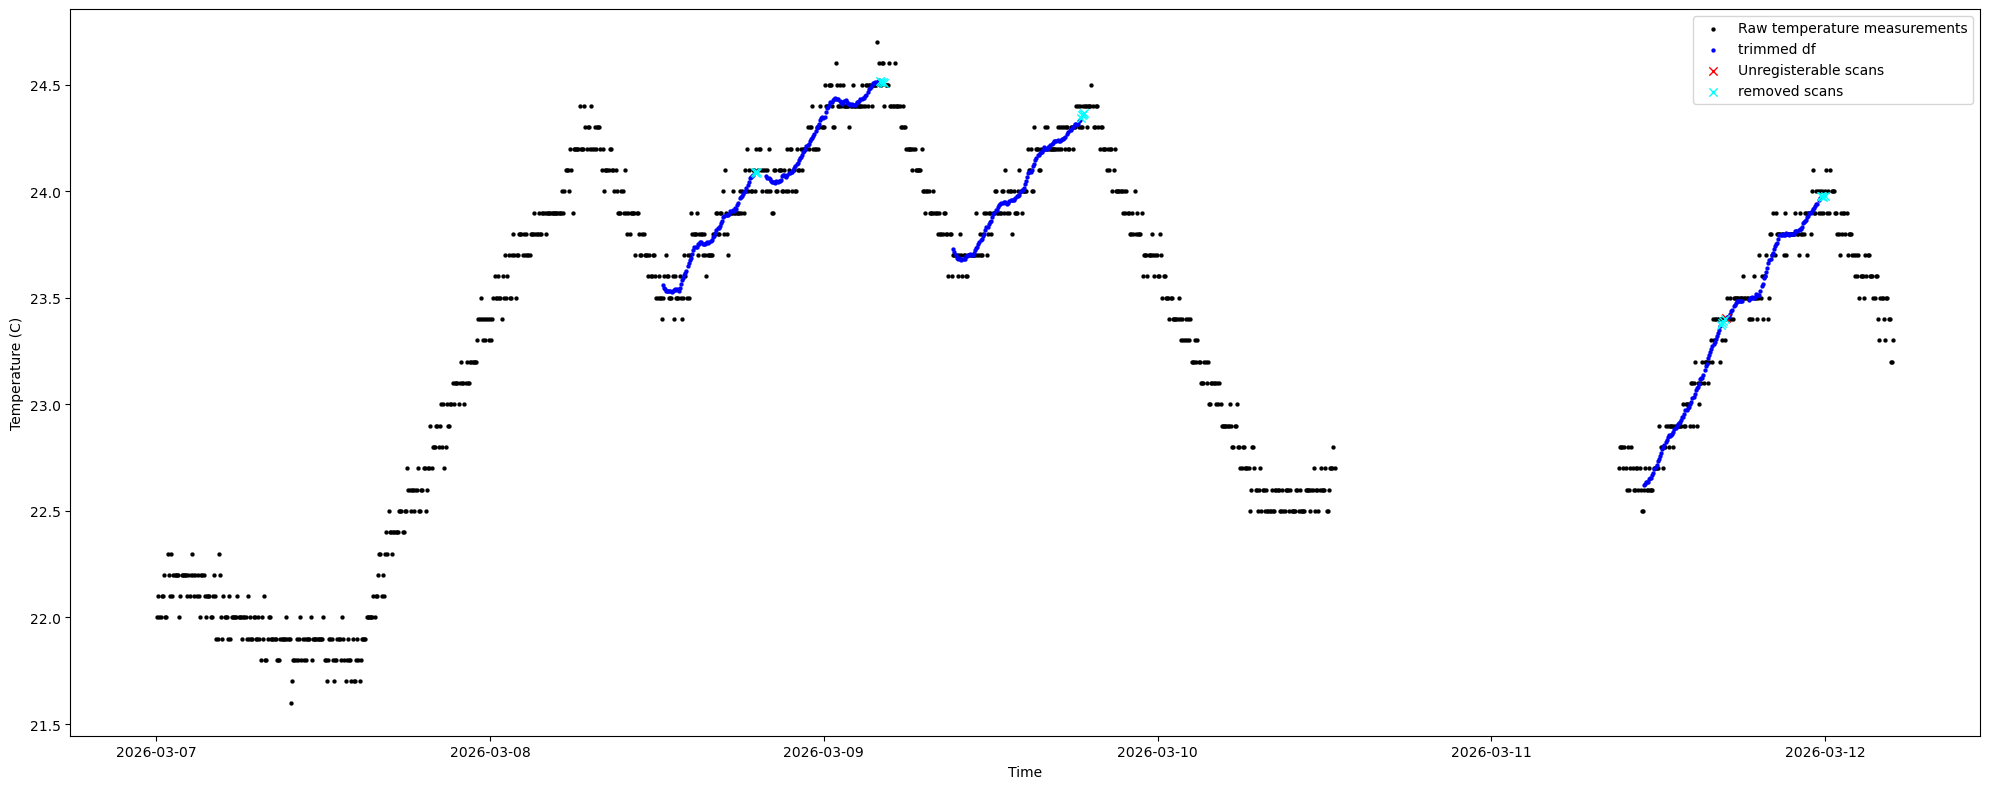

In [10]:
# -----------------------------
# remove incomplete sets of data
# -----------------------------

# data is collected in b-value sweeps of 5 scans (e.g. bx = 0, 200, 400, 600, 800)
# If we don't have a complete sweep of 5 scans we shall remove this sweep of scans.
# A less coarse implementation would be to only remove sweeps where the b=0 scan didn't
# make it through temperature pairing and registration successfully.

n_loop = 5 
i_b0 = reg_df.index[reg_df["b_value"] < 5].to_numpy()
di_b0 = np.diff(i_b0)
di_b0 = np.append(di_b0, reg_df.shape[0] - i_b0[-1])

i_drop_total = np.array([])
for i, di in zip(i_b0, di_b0):


    if di == n_loop:
        continue
    elif di < n_loop:
        i_drop = i + np.linspace(start=0, stop=di, num=di, endpoint=False)
    else:
        i_drop = i + np.linspace(start=n_loop, stop=di, num=di - n_loop, endpoint=False)
    i_drop_total = np.append(i_drop_total, i_drop)

trimmed_df = reg_df.drop(index=i_drop_total).reset_index(drop=True)
remove_df = reg_df.loc[i_drop_total].reset_index(drop=True)

print(f"Dataset now comprises a total of {trimmed_df.shape[0]} scans, {i_drop_total.size} scans trimmed")

fig, ax = plt.subplots(1, 1, figsize=(20,8))
ax.scatter(temp_log_dt_np[:,0], 
           temp_log_dt_np[:,1], 
           marker=".", 
           linewidth=0.1, 
           c="k", 
           label="Raw temperature measurements")

ax.scatter(trimmed_df["scan_time"].values, 
           trimmed_df["temperature"].values, 
           marker=".", 
           linewidth=0.1, 
           c="b",
           label="trimmed df")

ax.scatter(unreg_df["scan_time"].values, 
           unreg_df["temperature"].values, 
           marker="x", 
           linewidth=1, 
           c="r",
           label="Unregisterable scans")

ax.scatter(remove_df["scan_time"].values, 
           remove_df["temperature"].values, 
           marker="x", 
           linewidth=1, 
           c="cyan",
           label="removed scans")
ax.legend()
ax.set_ylabel("Temperature (C)")
ax.set_xlabel("Time")
fig.tight_layout()
plt.show()

# plot_num_of_repeats(trimmed_df, col_name="seq_name")

In [11]:
def median_abs_deviation(x):

    x = np.asarray(x)
    med = np.median(x)
    return np.median(np.abs(x - med))


def robust_zscore(x, scale_factor=1.4826):

    x = np.asarray(x)
    med = np.median(x)
    mad = median_abs_deviation(x)

    if mad == 0:
        # avoid division by zero; return zeros if no variability
        return np.zeros_like(x, dtype=float)

    return (x - med) / (scale_factor * mad)


def est_t1(temp, T1_21C = 3):

    TDC = 0.0237
    delta_temp = temp - 21
    t1 = T1_21C * (1 + TDC * delta_temp)
    return t1


def est_t2(temp, T2_21C = 2.6):
    TDC = 0.016
    delta_temp = temp - 21
    t2 = T2_21C * (1 + TDC * delta_temp)
    return t2


def M_ss(t1, TR=0.85, theta=np.pi/2):
    return np.sin(theta) * ((1-np.exp(-TR/t1))/(1-np.cos(theta) * np.exp(-TR/t1)))


def balance_dataframe(
    df,
    mask: np.ndarray = None,
    z_threshold: float = 3.5,
    image_col: str = "reg_image",
    verbose: bool = True,
):

    # image_col: column of registered images used to calculate the scan statistics for z-scoring
    log = print if verbose else (lambda *args, **kwargs: None)

    # -------------------------------------------------
    # mask setup
    # -------------------------------------------------
    if mask is None:
        b0_image = np.mean(
            df[df["b_value"] < 5][image_col].values,
            axis=0
        )

        _mask = reg.get_mask(
            b0_image,
            axis=-1
        ).squeeze().astype(bool)

    else:
        _mask = mask.astype(bool).copy()

    # -------------------------------------------------
    # group identifiers
    # -------------------------------------------------
    dur_values = sorted(df["dwi_grad_duration"].unique())
    axes_values = sorted(df["dwi_direction"].unique())

    # -------------------------------------------------
    # FIRST PASS
    # threshold-based filtering
    # determine minimum surviving repeat count
    # -------------------------------------------------
    first_pass_results = []
    kept_counts = []

    for axis, dur in tqdm(
        list(product(axes_values, dur_values)),
        desc="First pass",
        disable=not verbose
    ):

        subset_df = df[
            (df["dwi_direction"] == axis) &
            (df["dwi_grad_duration"] == dur)
        ]

        if subset_df.empty:
            continue

        group_data = np.stack(
            subset_df[image_col].values,
            axis=-1
        )

        group_b = subset_df["b_value"].values
        group_temp = subset_df["temperature"].values
        group_te = subset_df["TE"].values * 1e-3
        group_idx = subset_df.index.to_numpy()

        # ---------------------------------------------
        # scaling corrections
        # ---------------------------------------------
        group_adc_true = temp.water_diffusivity(
            group_temp,
            polynomial=True
        )

        e_bd = np.exp(-group_b * group_adc_true)

        sf_adc = (
            np.mean(e_bd) /
            np.maximum(e_bd, np.finfo(float).eps)
        )

        scaled_data = group_data * sf_adc

        t1 = est_t1(group_temp, T1_21C=3.0)
        t2 = est_t2(group_temp, T2_21C=2.6)

        sig_ss = M_ss(t1) * np.exp(-group_te / t2)

        sf_relaxivity = (
            np.mean(sig_ss) /
            np.maximum(sig_ss, np.finfo(float).eps)
        )

        scaled_data *= sf_relaxivity

        # ---------------------------------------------
        # threshold filtering per b-value
        # ---------------------------------------------
        b_unique = np.unique(group_b)

        for b in b_unique:

            ib = np.where(group_b == b)[0]

            if len(ib) == 0:
                continue

            b_scans = scaled_data[..., ib]

            # one scalar per scan
            b_scan_stat = np.median(
                b_scans[_mask, :],
                axis=0
            )

            z_scores = robust_zscore(b_scan_stat)

            keep_mask = np.abs(z_scores) < z_threshold

            kept_ib = ib[keep_mask]

            kept_counts.append(len(kept_ib))

            first_pass_results.append({
                "axis": axis,
                "dur": dur,
                "b": b,
                "ib": ib,
                "kept_ib": kept_ib,
                "z_scores": z_scores,
                "group_idx": group_idx,
            })

            # logging
            n_removed = len(ib) - len(kept_ib)

            log(
                f"[axis={axis}, dur={dur}, b={b}] "
                f"kept={len(kept_ib)} "
                f"removed={n_removed}"
            )

    # -------------------------------------------------
    # determine balanced repeat count
    # -------------------------------------------------
    if len(kept_counts) == 0:
        raise ValueError("No valid repeat groups found.")

    n_keep = np.min(kept_counts)

    log(f"\nBalanced repeat count: n_keep = {n_keep}")

    # -------------------------------------------------
    # SECOND PASS
    # select n_keep lowest-z scans
    # -------------------------------------------------
    keep_indices = []

    for result in first_pass_results:

        axis = result["axis"]
        dur = result["dur"]
        b = result["b"]

        kept_ib = result["kept_ib"]
        z_scores = result["z_scores"]
        group_idx = result["group_idx"]

        # z-scores corresponding only to surviving scans
        surviving_z = np.abs(
            z_scores[
                np.isin(result["ib"], kept_ib)
            ]
        )

        # rank surviving scans
        order = np.argsort(surviving_z)

        final_keep_ib = kept_ib[order[:n_keep]]

        # ---------------------------------------------
        # logging
        # ---------------------------------------------
        if len(kept_ib) > n_keep:

            largest_kept_z = surviving_z[order[n_keep - 1]]
            lowest_removed_z = surviving_z[order[n_keep]]

            log(
                f"[axis={axis}, dur={dur}, b={b}] "
                f"kept max |z|={largest_kept_z:.3f}, "
                f"removed min |z|={lowest_removed_z:.3f}"
            )

        else:

            log(
                f"[axis={axis}, dur={dur}, b={b}] "
                f"all surviving scans retained"
            )

        keep_indices.extend(
            group_idx[final_keep_ib].tolist()
        )

    # -------------------------------------------------
    # final dataframe
    # -------------------------------------------------
    balance_df = (
        df.loc[keep_indices]
        .copy()
        .reset_index(drop=True)
    )

    return balance_df


def plot_comparison(df, mask:np.ndarray=None, image_col: str = "reg_image"):

    axes_values = sorted(df["dwi_direction"].unique())

    lim = 0.1
    i_slice = df[image_col].values[0].shape[2] // 2

    for axis in axes_values:

        # b-values specific to this axis (rank-based coloring)
        axis_df = df[df["dwi_direction"] == axis]
        n_rep_max = axis_df["seq_name"].value_counts().max()
        axis_seqs = axis_df["seq_name"].unique()
        n_seqs = axis_seqs.shape[0]

        fig, axs = plt.subplots(n_seqs, n_rep_max, figsize=(n_rep_max*2.4, n_seqs*2.4))

        for i, (sn, seq_df) in enumerate(axis_df.groupby(by="seq_name")):

            #print(sn)

            group_data = np.stack(seq_df[image_col].values, axis=-1)
            group_b = seq_df["b_value"].unique()[0]
            group_temp = seq_df["temperature"].values
            group_adc_true = temp.water_diffusivity(group_temp, polynomial=True)
            group_te = seq_df["TE"].values * 1e-3

            e_bd = np.exp(-group_b * group_adc_true)
            sf_adc = (np.mean(e_bd) / e_bd)
            scaled_data = group_data * sf_adc

            t1 = est_t1(group_temp, T1_21C = 3.0)
            t2 = est_t2(group_temp, T2_21C = 2.6)
            
            sig_ss = M_ss(t1) * np.exp(-group_te/t2)
            sf_relaxivity = np.mean(sig_ss) / sig_ss
            
            scaled_data *= sf_relaxivity

            avg_image = np.mean(scaled_data, axis=-1, keepdims=True)
            diff_images = scaled_data - avg_image
            rel_diff = np.zeros_like(diff_images)
            rel_diff[mask==1] = diff_images[mask==1] / avg_image[mask==1]

            for j in range(rel_diff.shape[-1]):
                plotslice = rel_diff[:,:,i_slice, j]
                axs[i, j].imshow(plotslice, vmin=-lim, vmax=lim, cmap="RdBu_r")
                axs[i, j].set_axis_off()
                axs[i, j].set_title(f"Rep {j}", fontsize=7)
            
        
        fig.suptitle(f"Axis - {axis}")
        fig.tight_layout()
        
        plt.show()

### CHOOSE Z-SCORE THRESHOLD

In [12]:
# ---------------------------------------------------------------------------------
# The z-score threshold was originally tuned on the registered MP-PCA denoised scans.
# Scans are now z-scored on the registered noisy scans, so check how the choice of
# threshold changes the pruned dataset for each image type before settling on a value.
# ---------------------------------------------------------------------------------
thresholds = [2.0, 2.5, 3.0, 3.5]
rows = []
for z in thresholds:
    kept = {}
    for col in ["reg_mppca_image", "reg_image"]:
        bal = balance_dataframe(trimmed_df, mask=b0_mask, z_threshold=z, image_col=col, verbose=False)
        kept[col] = set(bal["scan_time"])
        rows.append({"z_threshold": z, "image_col": col, "n_scans_kept": bal.shape[0],
                     "n_repeats_per_seq": bal.groupby("seq_name").size().min()})

    both = len(kept["reg_mppca_image"] & kept["reg_image"])
    union = len(kept["reg_mppca_image"] | kept["reg_image"])
    rows[-1]["scans_in_common_with_mppca (%)"] = 100 * both / union

pd.DataFrame(rows)

,z_threshold,image_col,n_scans_kept,n_repeats_per_seq,scans_in_common_with_mppca (%)
0,2.0,reg_mppca_image,225,5,NaN
1,2.0,reg_image,225,5,90.677966
2,2.5,reg_mppca_image,270,6,NaN
3,2.5,reg_image,225,5,81.318681
4,3.0,reg_mppca_image,315,7,NaN
5,3.0,reg_image,315,7,98.738170
6,3.5,reg_mppca_image,315,7,NaN
7,3.5,reg_image,315,7,98.738170


First pass:   0%|          | 0/9 [00:00<?, ?it/s]

[axis=X, dur=0.03, b=0.03168196917377561] kept=9 removed=2
[axis=X, dur=0.03, b=200.1475879411287] kept=11 removed=0
[axis=X, dur=0.03, b=400.57464288887877] kept=8 removed=3
[axis=X, dur=0.03, b=601.0614105474428] kept=8 removed=3
[axis=X, dur=0.03, b=802.6574578638617] kept=7 removed=4
[axis=X, dur=0.035, b=0.03564392365944124] kept=9 removed=1
[axis=X, dur=0.035, b=200.13373687741472] kept=10 removed=0
[axis=X, dur=0.035, b=400.52183471013103] kept=10 removed=0
[axis=X, dur=0.035, b=600.7775723793945] kept=10 removed=0
[axis=X, dur=0.035, b=801.0281098931385] kept=6 removed=4
[axis=X, dur=0.04, b=0.039689287713226114] kept=8 removed=1
[axis=X, dur=0.04, b=200.17982509761896] kept=7 removed=2
[axis=X, dur=0.04, b=400.47481188076785] kept=9 removed=0
[axis=X, dur=0.04, b=600.7102703462413] kept=9 removed=0
[axis=X, dur=0.04, b=801.1763993813337] kept=9 removed=0
[axis=Y, dur=0.03, b=0.02975146914974664] kept=11 removed=0
[axis=Y, dur=0.03, b=200.28916135061573] kept=11 removed=0
[axis

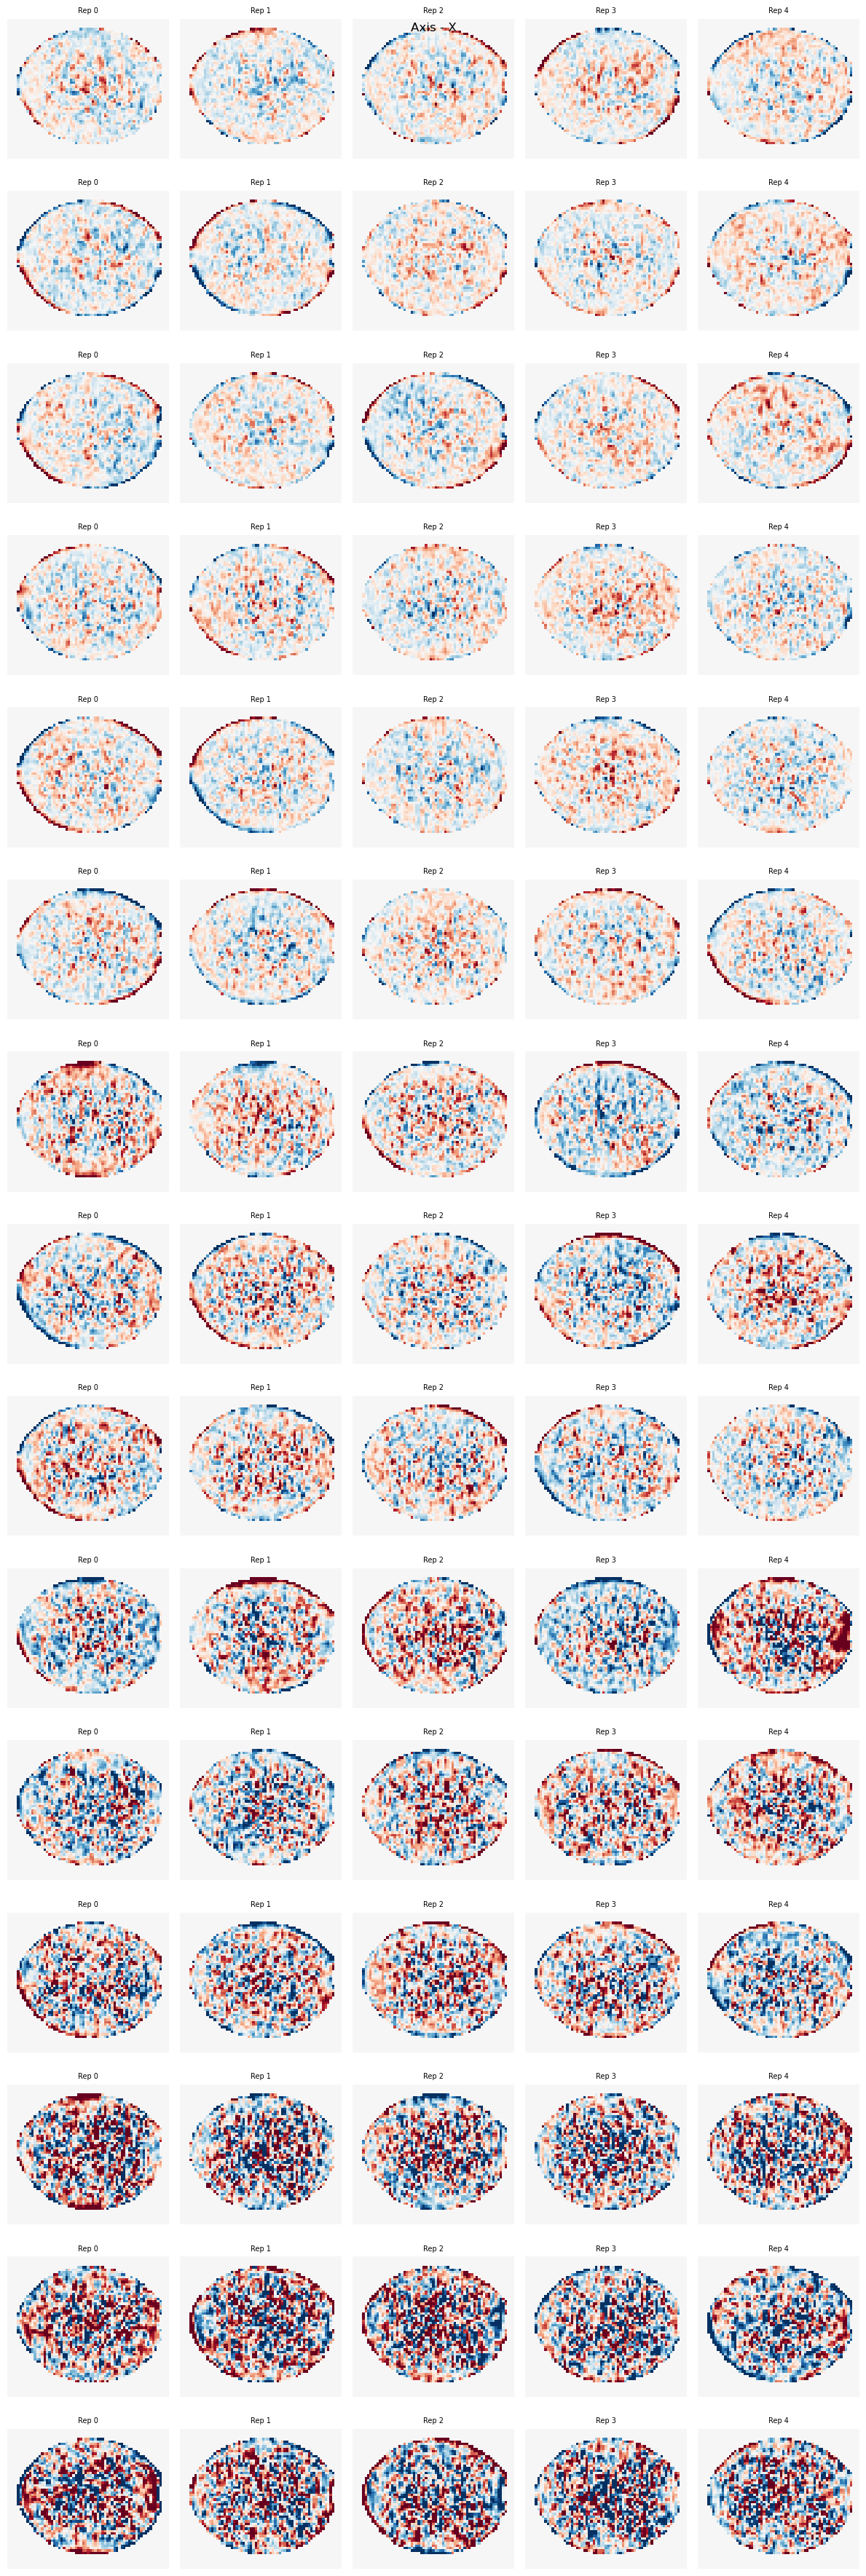

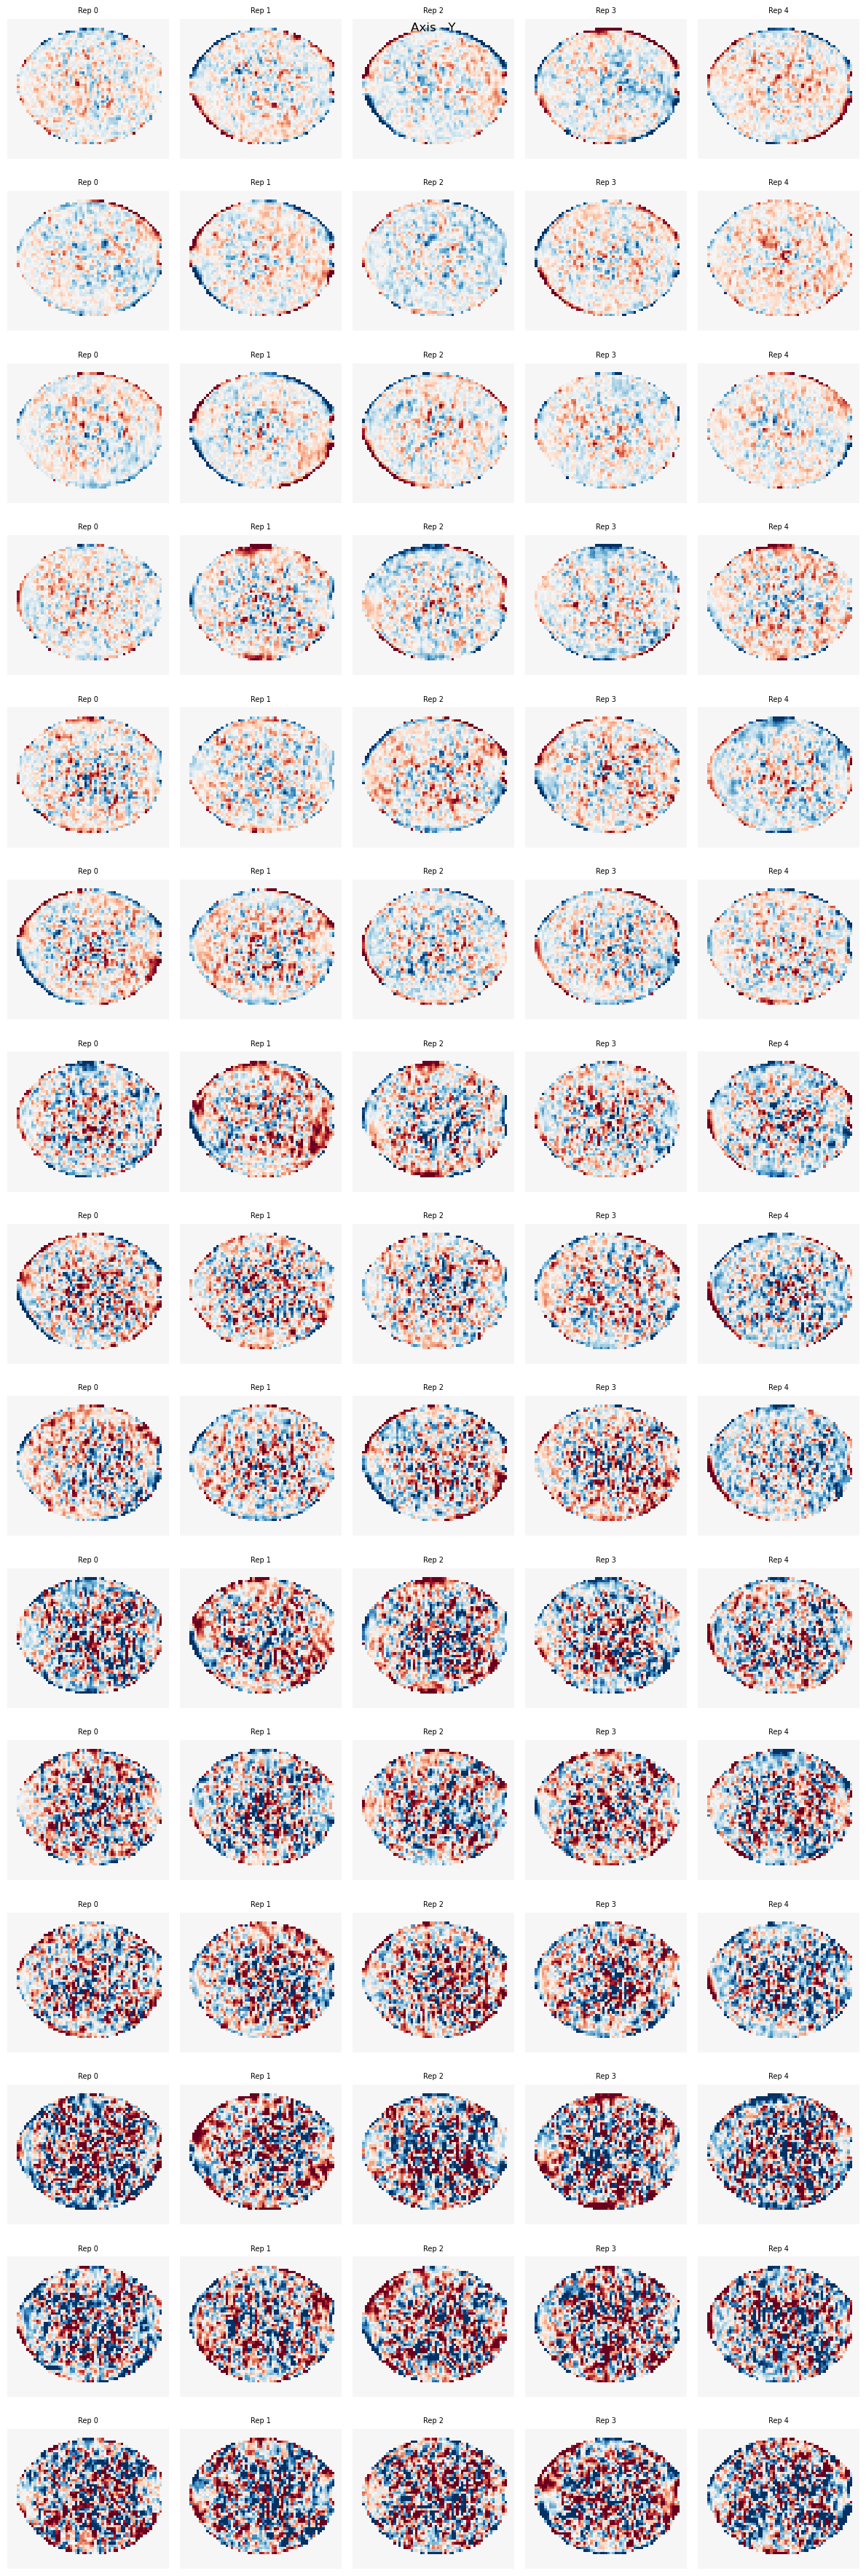

/var/folders/2x/cjhf7z5x01z_zb36hj149kqm0000gp/T/ipykernel_61162/3276411009.py:299: RuntimeWarning: invalid value encountered in divide
  rel_diff[mask==1] = diff_images[mask==1] / avg_image[mask==1]


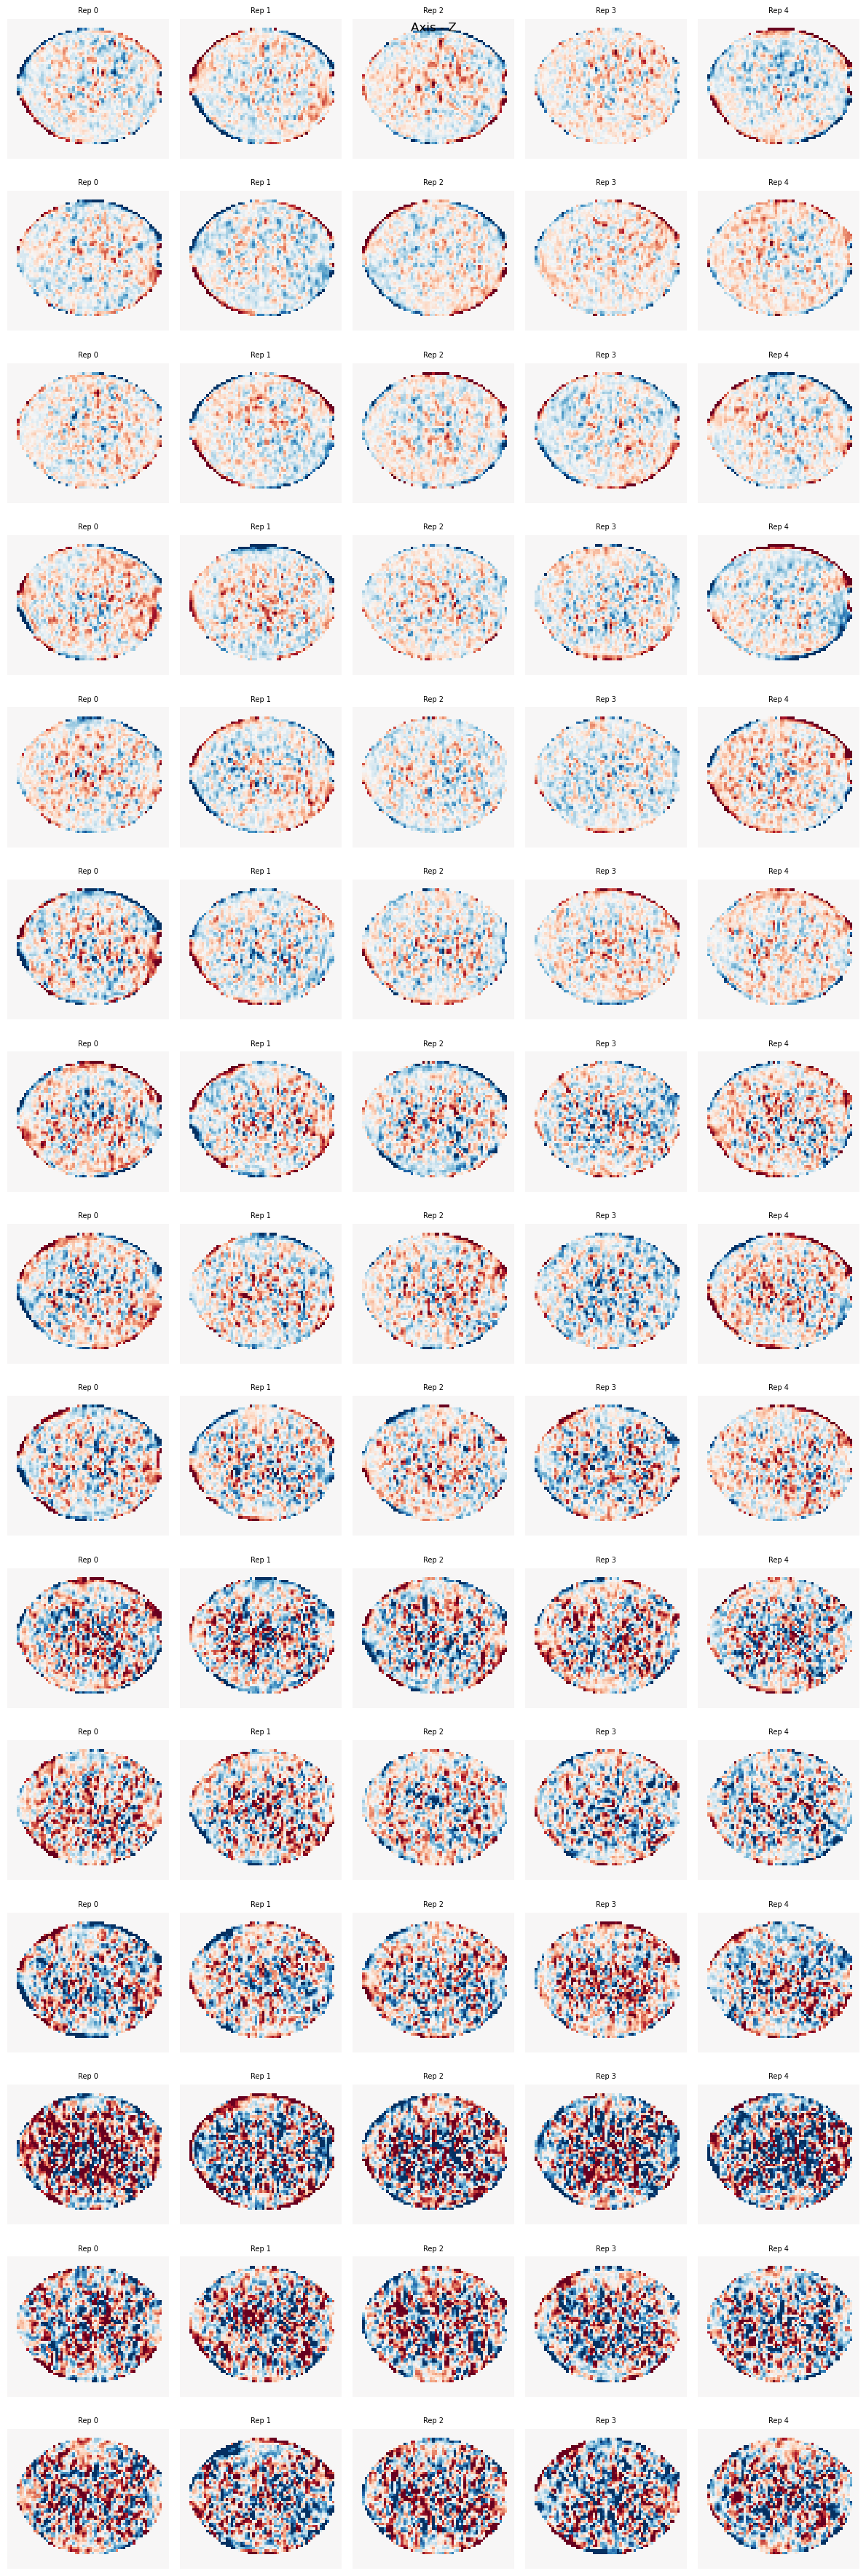

In [ ]:
# Prune using z-scores of the registered noisy scans
balance_df = balance_dataframe(trimmed_df, mask=b0_mask, z_threshold=3.5, image_col="reg_image")

plot_comparison(balance_df, mask=b0_mask, image_col="reg_image")

## SAVE OUTPUTS

In [14]:
# Original (noisy) and MP-PCA denoised scans, before registration
raw_images = np.stack(balance_df["image"].values, axis=-1)
raw_nii = nib.Nifti1Image(raw_images, affine=aff_0)
fio.save_nifti(raw_nii, OUTPUT_DIR, testname + "_" + "RAW.nii.gz")

dn_images = np.stack(balance_df["mppca_image"].values, axis=-1)
dn_nii = nib.Nifti1Image(dn_images, affine=aff_0)
fio.save_nifti(dn_nii, OUTPUT_DIR, testname + "_" + "RAW_MPPCA.nii.gz")

# Registered scans (transformations estimated on the MP-PCA scans and applied to both sets)
reg_images = np.stack(balance_df["reg_image"].values, axis=-1)
reg_nii = nib.Nifti1Image(reg_images, affine=aff_0)
fio.save_nifti(reg_nii, OUTPUT_DIR, testname + "_" + "RAW_REG.nii.gz")

reg_dn_images = np.stack(balance_df["reg_mppca_image"].values, axis=-1)
reg_dn_nii = nib.Nifti1Image(reg_dn_images, affine=aff_0)
fio.save_nifti(reg_dn_nii, OUTPUT_DIR, testname + "_" + "RAW_MPPCA_REG.nii.gz")

b0_mask_nii = nib.Nifti1Image(b0_mask.astype(float), aff_0)
fio.save_nifti(b0_mask_nii, OUTPUT_DIR, testname + "_" + "MASK.nii.gz")

# Registration transformations, in the same row order as the parameters file
transforms_fname = OUTPUT_DIR / (testname + "_" + "transforms.json")
with open(transforms_fname, "w") as f:
    json.dump(balance_df["transform"].tolist(), f)

param_df = balance_df.drop(["image", "mppca_image", "reg_image", "reg_mppca_image", "transform"], axis=1, inplace=False)
param_fname = OUTPUT_DIR / (testname + "_" + "params.h5")
param_df.to_hdf(param_fname, key="df", mode="w", index=False)

calibration_RAW.nii.gz saved
calibration_RAW_MPPCA.nii.gz saved
calibration_RAW_REG.nii.gz saved
calibration_RAW_MPPCA_REG.nii.gz saved
calibration_MASK.nii.gz saved


/var/folders/2x/cjhf7z5x01z_zb36hj149kqm0000gp/T/ipykernel_61162/711892176.py:29: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block0_values] [items->Index(['seq_name', 'dwi_direction', 'grad_vec', 'affine', 'spacing'], dtype='object')]

  param_df.to_hdf(param_fname, key="df", mode="w", index=False)
